# ДЗ 9. Выбор модели кадровой динамики
Команда «Движуха в кадрах»

Предсказываем, будет ли педагог отсутствовать в следующем годовом срезе. Если педагог сменил школу внутри системы, он остаётся в классе 0.

## 1. Какие модели возьмём из ДЗ 8
| Модель и балансировка в ДЗ 8 | Accuracy | Balanced accuracy |
|---|---:|---:|
| Дерево с весами классов | 0,640 | 0,604 |
| KNN со SMOTE | 0,652 | 0,570 |
| Логистическая регрессия без весов | 0,868 | 0,506 |

Все три модели предсказывали оба класса. При постоянном ответе balanced accuracy была бы 0,5. Дерево и KNN лучше распознавали редкий класс. Регрессия дала высокую общую точность, но редко находила уходы. Проверим её с весами классов.

Дополнительно сравним CatBoost, который мы выбрали в качестве основной модели для СППР. Обучим его заново на признаках ДЗ 8.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from catboost import CatBoostClassifier

## 2. Подготовка данных
Берём признаки из ДЗ 8 и оставляем одну запись на педагога за год. Учимся на 2022 году и проверяем прогноз на 2023. Для 2024 года исход пока неизвестен.

In [2]:
root = Path.cwd()
if not (root / 'HW').is_dir():
    root = root.parent

df = pd.read_parquet(root / 'HW/data/data_clean.parquet')
df = df.drop_duplicates(['id', 'year'])
outcomes = df.groupby('year')['target']
summary_by_year = outcomes.agg(['size', 'count'])
summary_by_year.columns = ['Всего педагогов', 'Известно исходов']
summary_by_year['Число уходов'] = outcomes.sum(min_count=1).astype('Int64')
display(summary_by_year)

numeric = ['age', 'experience_age_pedagogic_clean', 'experience_age_other_clean',
           'n_unique_subjects', 'n_unique_parallel', 'min_parallel', 'max_parallel']
binary = ['sex', 'class_manager']
categories = ['main_position_cat', 'academic_degree_cat', 'category_qual_cat']
features = numeric + binary + categories

train = df[df['year'] == 2022]
test = df[df['year'] == 2023]
X_train, y_train = train[features], train['target'].astype(int)
X_test, y_test = test[features], test['target'].astype(int)

,Всего педагогов,Известно исходов,Число уходов
year,,,
2022,17396,17396,2596
2023,17394,17394,2299
2024,17933,0,<NA>


## 3. Преобразования и модели
Пропуски в числовых признаках заменяем медианой. Категории переводим в столбцы 0/1. Для KNN и регрессии приводим числовые признаки к одному масштабу. Дереву масштабирование не требуется.

Дереву и регрессии задаём веса классов. Для KNN добавляем примеры редкого класса через SMOTE. Все преобразования обучаются внутри каждого фолда. После SMOTE отдельные индикаторы у искусственных примеров могут быть дробными.

Для CatBoost используем ту же подготовку, что для дерева, и автоматические веса классов. Так у двух моделей будут одинаковые входные столбцы.

In [3]:
scaled_numbers = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

def prepare(numbers):
    return ColumnTransformer([
        ('numbers', numbers, numeric),
        ('flags', 'passthrough', binary),
        ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categories)
    ])

tree = Pipeline([
    ('prepare', prepare(SimpleImputer(strategy='median'))),
    ('model', DecisionTreeClassifier(max_depth=3, min_samples_leaf=10,
                                     class_weight='balanced', random_state=42))
])
knn = ImbPipeline([
    ('prepare', prepare(scaled_numbers)),
    ('balance', SMOTE(random_state=42)),
    ('model', KNeighborsClassifier(n_neighbors=5))
])
lr = Pipeline([
    ('prepare', prepare(scaled_numbers)),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])
cat = Pipeline([
    ('prepare', prepare(SimpleImputer(strategy='median'))),
    ('model', CatBoostClassifier(depth=4, iterations=150, learning_rate=0.06,
                                 auto_class_weights='Balanced', random_seed=42,
                                 verbose=False, allow_writing_files=False, thread_count=2))
])

## 4. Подбор настроек внутри 2022 года
Делим данные на пять частей с близкими долями уходов. Каждая часть один раз служит проверочной. Сначала оцениваем начальные настройки, затем перебираем варианты на тех же разбиениях. Выбираем по среднему F1 класса 1. Эта метрика учитывает и долю найденных уходов, и точность предупреждений.

In [4]:
models = {'Дерево': tree, 'KNN': knn, 'Регрессия': lr, 'CatBoost': cat}
grids = {
    'CatBoost': {'model__depth': [4, 6], 'model__iterations': [150, 300]},
    'Дерево': {'model__max_depth': [3, 7], 'model__min_samples_leaf': [10, 40]},
    'KNN': {'model__n_neighbors': [5, 15], 'model__weights': ['uniform', 'distance']},
    'Регрессия': {'model__C': [0.1, 1], 'model__class_weight': ['balanced', {0: 1, 1: 3}]}
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
best_models = {}
summary = []
folds = []

for name, model in models.items():
    before = cross_validate(model, X_train, y_train, cv=cv, scoring='f1')
    search = GridSearchCV(model, grids[name], scoring=metrics, refit='f1', cv=cv,
                          error_score='raise')
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best = search.best_index_
    row = {'Модель': name, 'Параметры': search.best_params_,
           'F1 до': before['test_score'].mean()}
    for metric in metrics:
        row[metric] = search.cv_results_['mean_test_' + metric][best]
    summary.append(row)

    for i in range(5):
        fold = {'Модель': name, 'Фолд': i + 1}
        for metric in metrics:
            fold[metric] = search.cv_results_[f'split{i}_test_{metric}'][best]
        folds.append(fold)

In [5]:
pd.set_option('display.max_colwidth', 120)
scores = pd.DataFrame(summary).set_index('Модель')
display(scores.round(3))
display(pd.DataFrame(folds).round(3))
homework = scores.loc[['Дерево', 'KNN', 'Регрессия']]
winner = homework['f1'].idxmax()
print('Лидер с учётом CatBoost:', scores['f1'].idxmax())
print('Выбор среди трёх моделей ДЗ 8 по среднему F1:', winner)

,Параметры,F1 до,accuracy,precision,recall,f1,roc_auc
Модель,,,,,,,
Дерево,"{'model__max_depth': 7, 'model__min_samples_leaf': 40}",0.319,0.632,0.229,0.617,0.333,0.667
KNN,"{'model__n_neighbors': 15, 'model__weights': 'uniform'}",0.278,0.605,0.206,0.577,0.303,0.622
Регрессия,"{'model__C': 0.1, 'model__class_weight': 'balanced'}",0.325,0.641,0.226,0.580,0.326,0.657
CatBoost,"{'model__depth': 4, 'model__iterations': 300}",0.351,0.651,0.244,0.638,0.353,0.694


,Модель,Фолд,accuracy,precision,recall,f1,roc_auc
0,Дерево,1,0.636,0.237,0.648,0.347,0.676
1,Дерево,2,0.623,0.225,0.622,0.330,0.661
2,Дерево,3,0.631,0.234,0.649,0.344,0.685
3,Дерево,4,0.658,0.233,0.565,0.330,0.669
4,Дерево,5,0.611,0.214,0.601,0.316,0.646
5,KNN,1,0.599,0.202,0.573,0.299,0.628
6,KNN,2,0.603,0.199,0.547,0.292,0.604
7,KNN,3,0.604,0.212,0.611,0.315,0.625
8,KNN,4,0.607,0.206,0.572,0.303,0.628
9,KNN,5,0.612,0.210,0.580,0.308,0.624


Лидер с учётом CatBoost: CatBoost
Выбор среди трёх моделей ДЗ 8 по среднему F1: Дерево


## 5. Проверка на 2023 году
GridSearchCV уже обучил каждую модель с выбранными настройками на всём 2022 году. Теперь сравним прогнозы с фактом. Precision показывает долю подтверждённых уходов среди предупреждений, Recall показывает долю найденных уходов среди фактических. ROC-AUC оценивает качество ранжирования по вероятности ухода.

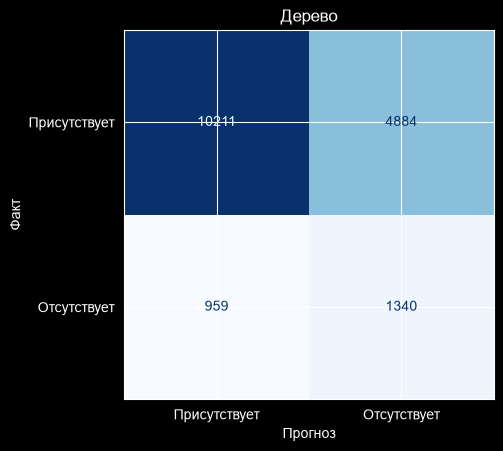

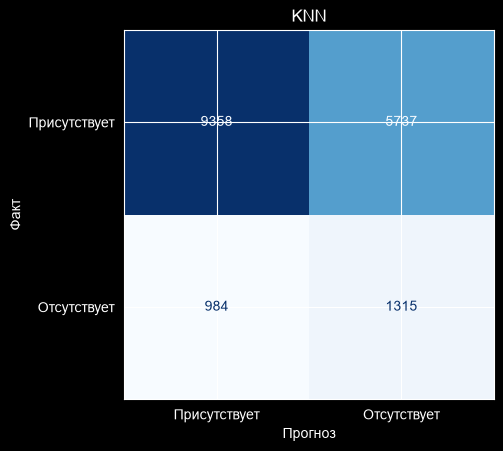

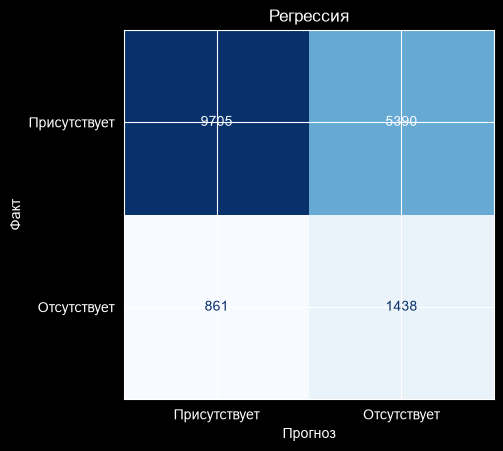

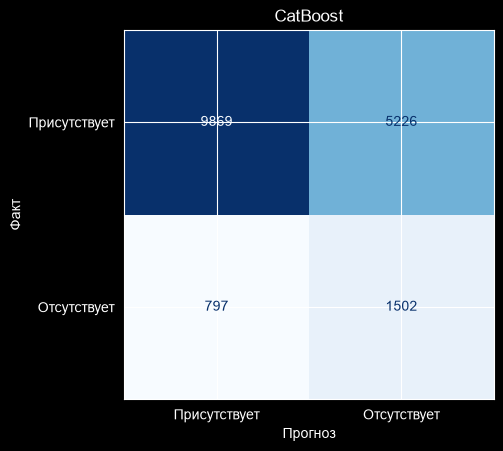

,accuracy,precision,recall,f1,roc_auc
Модель,,,,,
Дерево,0.664,0.215,0.583,0.314,0.683
KNN,0.614,0.186,0.572,0.281,0.636
Регрессия,0.641,0.211,0.625,0.315,0.682
CatBoost,0.654,0.223,0.653,0.333,0.710


In [6]:
results = []
for name, model in best_models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append([name, accuracy_score(y_test, prediction),
                    precision_score(y_test, prediction), recall_score(y_test, prediction),
                    f1_score(y_test, prediction), roc_auc_score(y_test, probability)])

    chart = ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, display_labels=['Присутствует', 'Отсутствует'],
        cmap='Blues', colorbar=False, values_format='d')
    chart.ax_.set(title=name, xlabel='Прогноз', ylabel='Факт')
    plt.show()

test_scores = pd.DataFrame(results, columns=['Модель'] + metrics).set_index('Модель')
display(test_scores.round(3))

## 6. Вывод
Сравним полноту на тесте и результат модели, выбранной по F1 до проверки на 2023 году.

In [7]:
leader = test_scores.loc[homework.index, 'recall'].idxmax()
print(f'По Recall среди трёх моделей ДЗ 8 лидирует {leader}. '
      f'Модель нашла {test_scores.loc[leader, "recall"]:.1%} фактических уходов.')
print(f'Финальная модель: {winner}. Средний F1 на фолдах 2022 года '
      f'{scores.loc[winner, "f1"]:.3f}, F1 на тесте {test_scores.loc[winner, "f1"]:.3f}.')
pred = best_models[winner].predict(X_test)
print('Пропущено уходов:', ((pred == 0) & (y_test == 1)).sum())
print('Ложные предупреждения:', ((pred == 1) & (y_test == 0)).sum())
print(f"CatBoost в этом опыте: средний F1 на фолдах {scores.loc['CatBoost', 'f1']:.3f}, "
      f"F1 на тесте {test_scores.loc['CatBoost', 'f1']:.3f}, "
      f"Recall на тесте {test_scores.loc['CatBoost', 'recall']:.1%}.")

По Recall среди трёх моделей ДЗ 8 лидирует Регрессия. Модель нашла 62.5% фактических уходов.
Финальная модель: Дерево. Средний F1 на фолдах 2022 года 0.333, F1 на тесте 0.314.
Пропущено уходов: 959
Ложные предупреждения: 4884
CatBoost в этом опыте: средний F1 на фолдах 0.353, F1 на тесте 0.333, Recall на тесте 65.3%.


Несмотря на хорошие результаты дерева, мы решили придерживаться выбора CatBoost в качестве модели для прогнозирования ухода, так как он всё равно обходит дерево по F1, Recall и ROC-AUC